# Do Companies with Stronger Financial Fundamentals Generate Higher Stock Returns?

Ruba Abdelgalil

A common assumption in investing is that "good" companies, the ones that are profitable, liquid, and not buried in debt, should also make good stocks. I wanted to see whether that actually holds up in the data. Using financial statements and stock prices for S&P 500 companies from the NYSE dataset on Kaggle, I test whether profitability, liquidity, leverage, and firm size are related to annual stock returns.

### Key Findings

- Financial fundamentals explain very little about stock returns. Most of the variation comes from how the overall market did that year.
- In the same year, companies with higher profit margins actually had lower returns, while companies with more liquidity did slightly better.
- None of that held up when I tried to predict the next year's returns. The only thing that stuck was size: bigger companies earned less, both in the same year and the year after.
- My takeaway is that markets seem to price in public accounting information pretty quickly, so it doesn't give investors much of an edge.

## Import Libraries

These are the libraries I used to clean the data, make charts, and run the regressions.

In [ ]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Data Collection

I downloaded the NYSE dataset from Kaggle. I used the split-adjusted price file because the regular one doesn't account for stock splits. Without that adjustment, a 2-for-1 split would look like the stock lost half its value overnight.

In [ ]:
path = kagglehub.dataset_download("dgawlik/nyse")

print("Path:", path)

Using Colab cache for faster access to the 'nyse' dataset.
Path: /kaggle/input/nyse


In [ ]:
fundamentals = pd.read_csv(path + "/fundamentals.csv")
prices = pd.read_csv(path + "/prices-split-adjusted.csv")

print("Fundamentals:", fundamentals.shape)
print("Prices:", prices.shape)

Fundamentals: (1781, 79)
Prices: (851264, 7)


In [ ]:
fundamentals.head()

,Unnamed: 0,Ticker Symbol,Period Ending,Accounts Payable,Accounts Receivable,Add'l income/expense items,After Tax ROE,Capital Expenditures,Capital Surplus,Cash Ratio,...,Total Current Assets,Total Current Liabilities,Total Equity,Total Liabilities,Total Liabilities & Equity,Total Revenue,Treasury Stock,For Year,Earnings Per Share,Estimated Shares Outstanding
0,0,AAL,2012-12-31,3.068000e+09,-222000000.0,-1.961000e+09,23.0,-1.888000e+09,4.695000e+09,53.0,...,7.072000e+09,9.011000e+09,-7.987000e+09,2.489100e+10,1.690400e+10,2.485500e+10,-367000000.0,2012.0,-5.60,3.350000e+08
1,1,AAL,2013-12-31,4.975000e+09,-93000000.0,-2.723000e+09,67.0,-3.114000e+09,1.059200e+10,75.0,...,1.432300e+10,1.380600e+10,-2.731000e+09,4.500900e+10,4.227800e+10,2.674300e+10,0.0,2013.0,-11.25,1.630222e+08
2,2,AAL,2014-12-31,4.668000e+09,-160000000.0,-1.500000e+08,143.0,-5.311000e+09,1.513500e+10,60.0,...,1.175000e+10,1.340400e+10,2.021000e+09,4.120400e+10,4.322500e+10,4.265000e+10,0.0,2014.0,4.02,7.169154e+08
3,3,AAL,2015-12-31,5.102000e+09,352000000.0,-7.080000e+08,135.0,-6.151000e+09,1.159100e+10,51.0,...,9.985000e+09,1.360500e+10,5.635000e+09,4.278000e+10,4.841500e+10,4.099000e+10,0.0,2015.0,11.39,6.681299e+08
4,4,AAP,2012-12-29,2.409453e+09,-89482000.0,6.000000e+05,32.0,-2.711820e+08,5.202150e+08,23.0,...,3.184200e+09,2.559638e+09,1.210694e+09,3.403120e+09,4.613814e+09,6.205003e+09,-27095000.0,2012.0,5.29,7.328355e+07


In [ ]:
prices.head()

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


## Data Preparation

To get annual returns, I took each company's last closing price of every year and calculated the percent change from the year before. Then I matched those returns to each company's financial statements for the same fiscal year and dropped rows with missing data.

In [ ]:
prices["date"] = pd.to_datetime(prices["date"], format="mixed")
prices["Year"] = prices["date"].dt.year

prices[["date", "Year"]].head()

,date,Year
0,2016-01-05,2016
1,2016-01-06,2016
2,2016-01-07,2016
3,2016-01-08,2016
4,2016-01-11,2016


In [ ]:
year_end_prices = (
    prices
    .sort_values(["symbol", "date"])
    .groupby(["symbol", "Year"], as_index=False)
    .last()
)

year_end_prices["AnnualReturn"] = (
    year_end_prices
    .groupby("symbol")["close"]
    .pct_change()
)

# Only keep a return when the previous row is the immediately preceding year
prev_year = year_end_prices.groupby("symbol")["Year"].shift(1)
year_end_prices.loc[year_end_prices["Year"] - prev_year != 1, "AnnualReturn"] = np.nan

year_end_prices.head(15)

,symbol,Year,date,open,close,low,high,volume,AnnualReturn
0,A,2010,2010-12-31,29.635193,29.635193,29.499285,29.828325,2050700.0,NaN
1,A,2011,2011-12-30,24.985693,24.985693,24.907009,25.400572,1930900.0,-0.156891
2,A,2012,2012-12-31,28.390558,29.284693,28.354792,29.306152,4707900.0,0.172058
3,A,2013,2013-12-31,41.094421,40.908440,40.829758,41.165951,1316000.0,0.396922
4,A,2014,2014-12-31,41.389999,40.939999,40.900002,41.790001,1421100.0,0.000771
5,A,2015,2015-12-31,41.900002,41.810001,41.720001,42.349998,1449300.0,0.021251
6,A,2016,2016-12-30,45.759998,45.560001,45.380001,45.820000,1216100.0,0.089691
7,AAL,2010,2010-12-31,10.160000,10.010000,9.950000,10.190000,2191900.0,NaN
8,AAL,2011,2011-12-30,5.190000,5.070000,5.050000,5.230000,5496300.0,-0.493506
9,AAL,2012,2012-12-31,12.850000,13.500000,12.840000,13.680000,7005600.0,1.662722


In [ ]:
fundamentals[["Ticker Symbol", "Period Ending", "For Year"]].head()

,Ticker Symbol,Period Ending,For Year
0,AAL,2012-12-31,2012.0
1,AAL,2013-12-31,2013.0
2,AAL,2014-12-31,2014.0
3,AAL,2015-12-31,2015.0
4,AAP,2012-12-29,2012.0


In [ ]:
# Some firms report more than one period in the same fiscal year; keep the latest one
fundamentals["Period Ending"] = pd.to_datetime(fundamentals["Period Ending"])

fundamentals = (
    fundamentals
    .sort_values(["Ticker Symbol", "Period Ending"])
    .drop_duplicates(subset=["Ticker Symbol", "For Year"], keep="last")
)

fundamentals.shape

(1740, 79)

In [ ]:
merged = fundamentals.merge(
    year_end_prices,
    left_on=["Ticker Symbol", "For Year"],
    right_on=["symbol", "Year"],
    how="inner"
)

merged.shape

(1584, 88)

### Constructing the Variables

Long-term debt and total assets are in raw dollars, which makes them hard to compare across companies of very different sizes. So I measured leverage as long-term debt divided by total assets, and firm size as the log of total assets, since asset values are extremely skewed (a handful of giant companies dwarf everyone else).

In [ ]:
merged = merged[merged["Total Assets"] > 0].copy()

merged["Leverage"] = merged["Long-Term Debt"] / merged["Total Assets"]
merged["LogTotalAssets"] = np.log(merged["Total Assets"])

predictors = [
    "After Tax ROE",
    "Profit Margin",
    "Current Ratio",
    "Leverage",
    "Gross Margin",
    "LogTotalAssets"
]

analysis = merged[["Ticker Symbol", "Year", "AnnualReturn"] + predictors].copy()

analysis.isnull().sum()

,0
Ticker Symbol,0
Year,0
AnnualReturn,20
After Tax ROE,0
Profit Margin,0
Current Ratio,262
Leverage,0
Gross Margin,0
LogTotalAssets,0


In [ ]:
analysis = analysis.dropna()

analysis.shape

(1305, 9)

### Handling Extreme Values

Financial ratios tend to have a few wild outliers that can pull a regression around. To limit that, I winsorized each variable at the 1st and 99th percentiles, which just means anything beyond those cutoffs gets capped at the cutoff.

In [ ]:
for col in ["AnnualReturn"] + predictors:
    lower, upper = analysis[col].quantile([0.01, 0.99])
    analysis[col] = analysis[col].clip(lower, upper)

## Exploratory Data Analysis

Before running any regressions, I looked at summary statistics, a correlation matrix, and a scatter plot to get a feel for the data and to check whether any of the variables were too closely related to each other.

In [ ]:
analysis[['AnnualReturn'] + predictors].describe().round(2)

,AnnualReturn,After Tax ROE,Profit Margin,Current Ratio,Leverage,Gross Margin,LogTotalAssets
count,1305.00,1305.00,1305.00,1305.00,1305.00,1305.00,1305.00
mean,0.16,33.15,12.21,182.63,0.26,46.63,23.34
std,0.28,63.89,10.87,113.75,0.16,22.07,1.09
min,-0.48,1.00,1.00,44.08,0.00,6.00,21.33
25%,-0.01,11.00,6.00,109.00,0.15,31.00,22.54
50%,0.14,18.00,10.00,149.00,0.24,43.00,23.29
75%,0.31,28.00,15.00,223.00,0.34,61.00,24.16
max,1.05,491.68,75.72,637.88,0.79,100.00,26.26


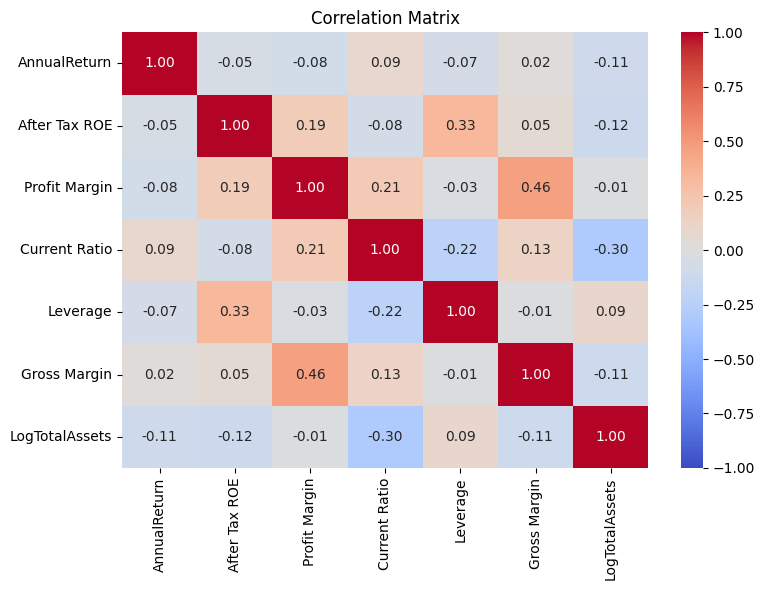

In [ ]:
correlation = analysis[["AnnualReturn"] + predictors].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

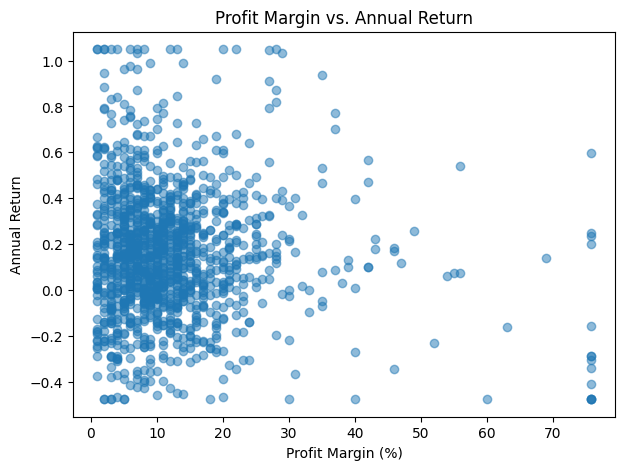

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(analysis["Profit Margin"], analysis["AnnualReturn"], alpha=0.5)
plt.xlabel("Profit Margin (%)")
plt.ylabel("Annual Return")
plt.title("Profit Margin vs. Annual Return")
plt.show()

## Regression Model

The main model regresses annual stock returns on six fundamentals: after-tax ROE, profit margin, and gross margin (profitability), current ratio (liquidity), leverage, and log total assets (size).

I also included year fixed effects. Stock returns swing a lot from year to year with the overall market, and I didn't want a good or bad market year to get mixed up with the effect of a company's finances. This way, the model compares companies within the same year.

In [ ]:
year_dummies = pd.get_dummies(analysis["Year"], prefix="Year", drop_first=True, dtype=float)

X = pd.concat([analysis[predictors], year_dummies], axis=1)
X = sm.add_constant(X)
y = analysis["AnnualReturn"]

model = sm.OLS(y, X)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           AnnualReturn   R-squared:                       0.244
Model:                            OLS   Adj. R-squared:                  0.238
Method:                 Least Squares   F-statistic:                     41.76
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           6.97e-72
Time:                        03:13:51   Log-Likelihood:                -6.9662
No. Observations:                1305   AIC:                             35.93
Df Residuals:                    1294   BIC:                             92.85
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.5690      0.163      3.

## Model Diagnostics

Here I check for multicollinearity using variance inflation factors (VIFs) and re-estimate the model with standard errors clustered by company. Clustering matters because the same company shows up in multiple years, and its returns from one year to the next aren't fully independent.

In [ ]:
X_vif = sm.add_constant(analysis[predictors])

vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})

print(vif[vif["Variable"] != "const"].round(2).to_string(index=False))

      Variable  VIF
 After Tax ROE 1.22
 Profit Margin 1.40
 Current Ratio 1.22
      Leverage 1.18
  Gross Margin 1.29
LogTotalAssets 1.16


In [ ]:
robust_results = model.fit(
    cov_type="cluster",
    cov_kwds={"groups": pd.factorize(analysis["Ticker Symbol"])[0]}
)

print(robust_results.summary())

                            OLS Regression Results                            
Dep. Variable:           AnnualReturn   R-squared:                       0.244
Model:                            OLS   Adj. R-squared:                  0.238
Method:                 Least Squares   F-statistic:                     46.98
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           1.73e-59
Time:                        03:13:51   Log-Likelihood:                -6.9662
No. Observations:                1305   AIC:                             35.93
Df Residuals:                    1294   BIC:                             92.85
Df Model:                          10                                         
Covariance Type:              cluster                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.5690      0.169      3.

In [ ]:
# Compact table of the coefficients of interest (firm-clustered standard errors)
summary_table = pd.DataFrame({
    "Coefficient": robust_results.params[predictors],
    "Std. Error": robust_results.bse[predictors],
    "p-value": robust_results.pvalues[predictors]
}).round(4)

print("Observations:", int(robust_results.nobs))
print("R-squared:", round(robust_results.rsquared, 3))
summary_table

Observations: 1305
R-squared: 0.244


,Coefficient,Std. Error,p-value
After Tax ROE,-0.0000,0.0001,0.9918
Profit Margin,-0.0022,0.0008,0.0090
Current Ratio,0.0002,0.0001,0.0295
Leverage,0.0063,0.0507,0.9007
Gross Margin,0.0006,0.0004,0.1457
LogTotalAssets,-0.0187,0.0071,0.0086


### How Much Do Fundamentals Explain?

The R-squared above includes the year controls, so on its own it's a little misleading. To see what the fundamentals actually add, I compared it to a model with only the year controls.

In [ ]:
year_only = sm.OLS(y, sm.add_constant(year_dummies)).fit()

print("R-squared, year controls only:        ", round(year_only.rsquared, 3))
print("R-squared, year controls + fundamentals:", round(results.rsquared, 3))
print("Added by fundamentals:                 ", round(results.rsquared - year_only.rsquared, 3))

R-squared, year controls only:         0.228
R-squared, year controls + fundamentals: 0.244
Added by fundamentals:                  0.016


## Additional Analysis: Do Fundamentals Predict Next Year's Returns?

The main model has a timing problem. It compares a company's financial statements to its stock return in the same year, but annual reports come out after the year is over, so no investor could have traded on that information at the time.

A fairer test is whether this year's fundamentals can predict next year's return. That's the question an actual investor would be asking.

In [ ]:
next_year = year_end_prices[["symbol", "Year", "AnnualReturn"]].copy()
next_year["Year"] = next_year["Year"] - 1
next_year = next_year.rename(columns={"AnnualReturn": "NextYearReturn"})

predictive = analysis.merge(
    next_year,
    left_on=["Ticker Symbol", "Year"],
    right_on=["symbol", "Year"],
    how="inner"
).dropna(subset=["NextYearReturn"])

lower, upper = predictive["NextYearReturn"].quantile([0.01, 0.99])
predictive["NextYearReturn"] = predictive["NextYearReturn"].clip(lower, upper)

pred_dummies = pd.get_dummies(predictive["Year"], prefix="Year", drop_first=True, dtype=float)
X_pred = sm.add_constant(pd.concat([predictive[predictors], pred_dummies], axis=1))

predictive_results = sm.OLS(predictive["NextYearReturn"], X_pred).fit(
    cov_type="cluster",
    cov_kwds={"groups": pd.factorize(predictive["Ticker Symbol"])[0]}
)

predictive_table = pd.DataFrame({
    "Coefficient": predictive_results.params[predictors],
    "Std. Error": predictive_results.bse[predictors],
    "p-value": predictive_results.pvalues[predictors]
}).round(4)

print("Observations:", int(predictive_results.nobs))
print("R-squared:", round(predictive_results.rsquared, 3))
print(predictive_table)

Observations: 1221
R-squared: 0.178
                Coefficient  Std. Error  p-value
After Tax ROE        0.0001      0.0001   0.3514
Profit Margin        0.0011      0.0009   0.1959
Current Ratio        0.0001      0.0001   0.3547
Leverage             0.0040      0.0393   0.9197
Gross Margin        -0.0005      0.0003   0.1384
LogTotalAssets      -0.0195      0.0055   0.0004


## Comparing Effect Sizes

The raw coefficients are hard to compare since the variables are in different units: percentages, ratios, and logged dollars. That's also why the regression output warns about a large condition number. It's a units issue, not a real problem, and the VIFs above (all under 1.5) back that up.

To make the variables comparable, I standardized them. Each coefficient below shows how many percentage points the annual return changes when a variable goes up by one standard deviation. The chart puts the same-year and next-year models side by side.

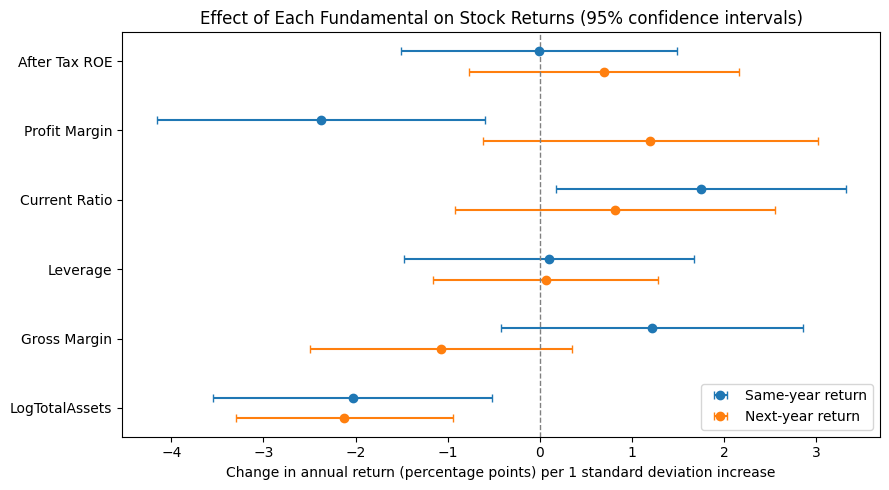

           Model       Variable   Coef    Low   High  p-value
Same-year return  After Tax ROE -0.008 -1.503  1.487    0.992
Same-year return  Profit Margin -2.377 -4.160 -0.594    0.009
Same-year return  Current Ratio  1.746  0.174  3.319    0.030
Same-year return       Leverage  0.100 -1.472  1.672    0.901
Same-year return   Gross Margin  1.218 -0.423  2.860    0.146
Same-year return LogTotalAssets -2.030 -3.544 -0.516    0.009
Next-year return  After Tax ROE  0.698 -0.770  2.166    0.351
Next-year return  Profit Margin  1.200 -0.619  3.019    0.196
Next-year return  Current Ratio  0.820 -0.917  2.557    0.355
Next-year return       Leverage  0.063 -1.154  1.279    0.920
Next-year return   Gross Margin -1.072 -2.490  0.346    0.138
Next-year return LogTotalAssets -2.120 -3.298 -0.942    0.000


In [ ]:
def standardized_coefs(data, outcome, label):
    z = data[predictors].apply(lambda s: (s - s.mean()) / s.std())
    dummies = pd.get_dummies(data["Year"], prefix="Year", drop_first=True, dtype=float)
    Xz = sm.add_constant(pd.concat([z, dummies], axis=1))
    res = sm.OLS(data[outcome], Xz).fit(
        cov_type="cluster",
        cov_kwds={"groups": pd.factorize(data["Ticker Symbol"])[0]}
    )
    ci = res.conf_int().loc[predictors]
    return pd.DataFrame({
        "Model": label,
        "Variable": predictors,
        "Coef": res.params[predictors].values * 100,
        "Low": ci[0].values * 100,
        "High": ci[1].values * 100,
        "p-value": res.pvalues[predictors].values
    })

coefs = pd.concat([
    standardized_coefs(analysis, "AnnualReturn", "Same-year return"),
    standardized_coefs(predictive, "NextYearReturn", "Next-year return")
])

fig, ax = plt.subplots(figsize=(9, 5))
offsets = {"Same-year return": -0.15, "Next-year return": 0.15}
for label in offsets:
    g = coefs[coefs["Model"] == label]
    ypos = np.arange(len(predictors)) + offsets[label]
    ax.errorbar(
        g["Coef"], ypos,
        xerr=[g["Coef"] - g["Low"], g["High"] - g["Coef"]],
        fmt="o", capsize=3, label=label
    )
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_yticks(np.arange(len(predictors)))
ax.set_yticklabels(predictors)
ax.invert_yaxis()
ax.set_xlabel("Change in annual return (percentage points) per 1 standard deviation increase")
ax.set_title("Effect of Each Fundamental on Stock Returns (95% confidence intervals)")
ax.legend()
plt.tight_layout()
plt.show()

print(coefs.round(3).to_string(index=False))

## Conclusion

I set out to test whether companies with stronger financial fundamentals earn higher stock returns. Based on 1,305 observations of S&P 500 companies from 2012 to 2016, the short answer is: not really, at least not in a way an investor could use.

Looking at same-year returns (after controlling for each year's overall market and clustering by company), three variables stood out. Companies with higher profit margins actually had lower returns, about 2.4 percentage points lower for each standard deviation increase (p = 0.009). That surprised me, since it's the opposite of what the "strong fundamentals" idea predicts. My best guess is that very profitable companies are already priced at a premium, so there's less room for the stock to climb. Companies with a higher current ratio did a bit better (+1.7 points, p = 0.030), and larger companies did worse (−2.0 points, p = 0.009), which lines up with the well-known size effect. ROE, gross margin, and leverage didn't show any meaningful relationship.

The bigger picture is that fundamentals explain very little. The year controls alone explain about 22.8% of the variation in returns, and adding all six financial variables only brings that up to 24.4%. How the overall market did in a given year matters far more than anything on a company's balance sheet.

The next-year test was the most telling part. When I used this year's fundamentals to predict next year's return, the profit margin and liquidity effects disappeared, and the profit margin estimate even flipped sign. Only size held up (−2.1 points, p < 0.001). To me, this suggests that once financial statements are public, the market prices that information in quickly, which fits the efficient market hypothesis. The size effect is the one exception, and it's consistent with a lot of earlier research.

Overall, strong fundamentals don't seem to translate reliably into higher stock returns. The relationships I found are small, show up mostly in same-year returns, and aren't much help for predicting what happens next.

### Limitations

There are a few things I'd want to address with more time and data:

- **Survivorship bias.** The dataset only includes companies that were in the S&P 500 when it was put together, so companies that got dropped or went bankrupt are probably missing. That could make average returns look better than they really were.
- **No risk adjustment.** I didn't adjust returns for market risk or other known factors like value or momentum, so part of the size effect could just reflect differences in risk.
- **Price returns only.** Returns don't include dividends, which understates how well high-dividend companies actually did for investors.
- **Short time period.** Five years is a small slice of market history, so these results might not hold in other periods or for smaller companies.